# DSCI 552 — Homework 5

- **Name:** Karan Timmala
- **GitHub Username:** karantimmala
- **USC ID:** 1373267232

The analysis follows the supplied assignment and uses the accompanying patient
and community datasets. Regression test error is measured by mean squared error
(MSE). The first 1,495 community observations are reserved for training; the last
499 are held out for evaluation. Run the cells in order from a fresh kernel.


In [1]:
# Optional setup in Jupyter, only when the package is unavailable:
# %pip install xgboost


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree, export_text
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

def locate_dataset(filename):
    for folder in (Path.cwd(), Path.cwd().parent):
        for subfolder in ("", "data", "upload"):
            candidate = folder / subfolder / filename
            if candidate.is_file():
                return candidate
    raise FileNotFoundError(
        f"Cannot locate {filename}. Put it beside this notebook or in a data/upload folder."
    )

# 1. Decision Trees as Interpretable Models

### (a) Download the Acute Inflammations data.

The supplied patient file is used directly. Its temperature field initially
contains decimal commas, and the remaining fields contain Yes/No categories.
The following cells convert these into values that the classifiers can use.


In [3]:
# Read the eight patient fields from the supplied tab-separated file.
patient_records = pd.read_csv(locate_dataset('diagnosis.data'), encoding='utf-16', sep='\t', header=None)
patient_fields = ['Temperature', 'Nausea', 'Lumbar_Pain', 'Urine_Pushing', 'Micturition_Pains', 'Burning_Urethra', 'Inflammation_Bladder', 'Nephritis']
patient_records.columns = patient_fields
patient_records.head()

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Inflammation_Bladder,Nephritis
0,"35,5",no,yes,no,no,no,no,no
1,"35,9",no,no,yes,yes,yes,yes,no
2,"35,9",no,yes,no,no,no,no,no
3,"36,0",no,no,yes,yes,yes,yes,no
4,"36,0",no,yes,no,no,no,no,no


In [4]:
# Replace decimal commas so temperature is stored as a numeric measurement.
patient_records['Temperature'] = patient_records['Temperature'].astype(str).str.replace(',', '.').astype(float)
patient_records.head()


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Inflammation_Bladder,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [5]:
# Encode symptoms and diagnosis labels using 1 for yes and 0 for no.
for field in patient_records.columns[1:]:
    patient_records[field] = patient_records[field].astype(str).str.strip().str.lower().map({'yes': 1, 'no': 0})
patient_records.head()


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Inflammation_Bladder,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree on the whole data set and plot it.

I use binary relevance: one classifier predicts bladder inflammation, and a
second predicts nephritis. Both receive the same six symptom variables and all
120 records. This approach is permitted by the assignment; combining the two
labels into a single multiclass response would be another valid choice.


In [6]:
# Use the six symptoms to predict each diagnosis separately.
symptom_matrix = patient_records.drop(columns=['Inflammation_Bladder', 'Nephritis'])
bladder_response = patient_records['Inflammation_Bladder']


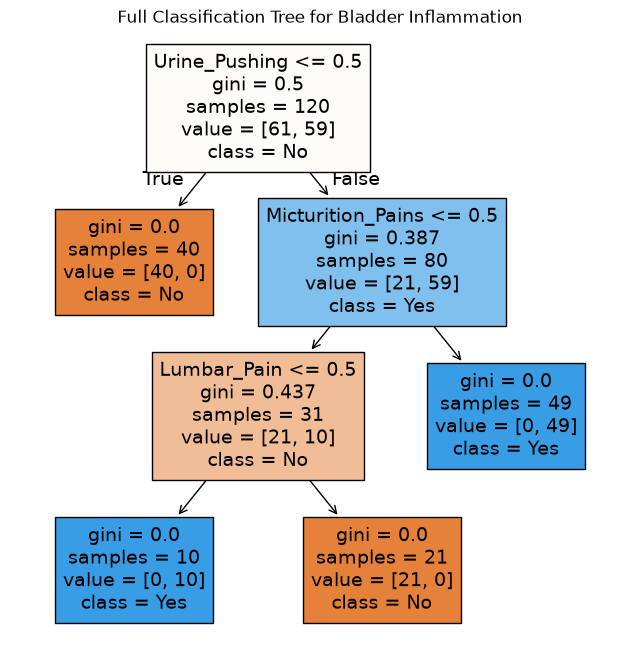

In [7]:
# Fit and draw the bladder classifier using every patient record.
bladder_classifier = DecisionTreeClassifier(random_state=0)
bladder_classifier.fit(symptom_matrix, bladder_response)
plt.figure(figsize=(8, 8))
plot_tree(bladder_classifier, feature_names=symptom_matrix.columns, class_names=['No', 'Yes'], filled=True)
plt.title('Full Classification Tree for Bladder Inflammation')
plt.show()


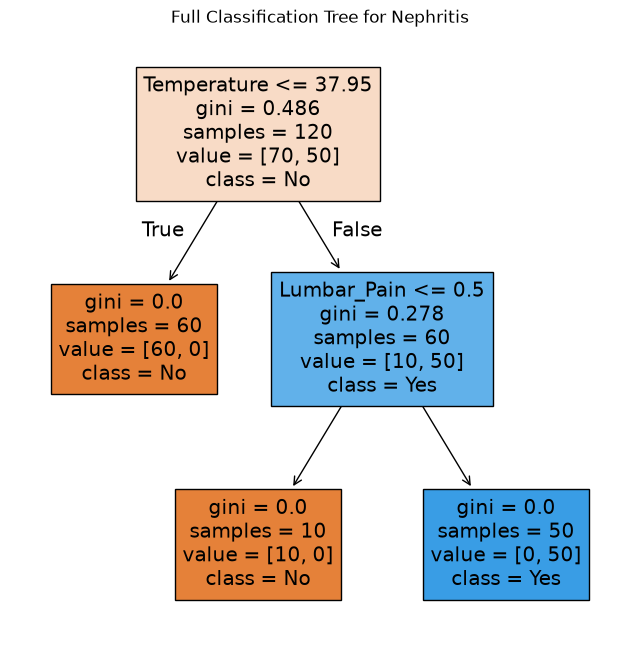

In [8]:
# Fit the second classifier for the nephritis diagnosis.
kidney_response = patient_records['Nephritis']
kidney_classifier = DecisionTreeClassifier(random_state=0)
kidney_classifier.fit(symptom_matrix, kidney_response)
plt.figure(figsize=(8, 8))
plot_tree(kidney_classifier, feature_names=symptom_matrix.columns, class_names=['No', 'Yes'], filled=True)
plt.title('Full Classification Tree for Nephritis')
plt.show()


### (c) Convert the decision rules into a set of IF-THEN rules.

A complete path from the root to a terminal node forms one IF–THEN rule.
The conditions specify which symptom values lead to a Yes or No prediction for
the diagnosis named in the output heading. With binary coding, a cutoff of 0.5
separates No (0) from Yes (1).


In [9]:
# Follow each root-to-leaf path and print its conditions and predicted label.
def describe_leaf_rules(fitted_tree, input_labels, outcome_labels):
    tree_structure = fitted_tree.tree_
    node_feature_names = [input_labels[candidate_index] if candidate_index != _tree.TREE_UNDEFINED else 'undefined!' for candidate_index in tree_structure.feature]

    def trace_branches(position, level, checks):
        if tree_structure.feature[position] != _tree.TREE_UNDEFINED:
            symptom_label = node_feature_names[position]
            split_point = tree_structure.threshold[position]
            trace_branches(tree_structure.children_left[position], level + 1, checks + [f'{symptom_label} <= {split_point:.2f}'])
            trace_branches(tree_structure.children_right[position], level + 1, checks + [f'{symptom_label} > {split_point:.2f}'])
        else:
            winning_index = tree_structure.value[position][0].argmax()
            predicted_outcome = outcome_labels[winning_index]
            print('IF ' + ' AND '.join(checks) + f' THEN {predicted_outcome}')
    trace_branches(0, 1, [])


In [10]:
# Display both the tree outline and the explicit bladder diagnosis rules.
print('Bladder inflammation: rules from the full tree')
bladder_rule_text = export_text(bladder_classifier, feature_names=list(symptom_matrix.columns))
print(bladder_rule_text)
describe_leaf_rules(bladder_classifier, list(symptom_matrix.columns), ['No', 'Yes'])


Bladder inflammation: rules from the full tree
|--- Urine_Pushing <= 0.50
|   |--- class: 0
|--- Urine_Pushing >  0.50
|   |--- Micturition_Pains <= 0.50
|   |   |--- Lumbar_Pain <= 0.50
|   |   |   |--- class: 1
|   |   |--- Lumbar_Pain >  0.50
|   |   |   |--- class: 0
|   |--- Micturition_Pains >  0.50
|   |   |--- class: 1

IF Urine_Pushing <= 0.50 THEN No
IF Urine_Pushing > 0.50 AND Micturition_Pains <= 0.50 AND Lumbar_Pain <= 0.50 THEN Yes
IF Urine_Pushing > 0.50 AND Micturition_Pains <= 0.50 AND Lumbar_Pain > 0.50 THEN No
IF Urine_Pushing > 0.50 AND Micturition_Pains > 0.50 THEN Yes


In [11]:
# Display the corresponding rules for nephritis.
print('Nephritis: rules from the full tree')
kidney_rule_text = export_text(kidney_classifier, feature_names=list(symptom_matrix.columns))
print(kidney_rule_text)
describe_leaf_rules(kidney_classifier, list(symptom_matrix.columns), ['No', 'Yes'])


Nephritis: rules from the full tree
|--- Temperature <= 37.95
|   |--- class: 0
|--- Temperature >  37.95
|   |--- Lumbar_Pain <= 0.50
|   |   |--- class: 0
|   |--- Lumbar_Pain >  0.50
|   |   |--- class: 1

IF Temperature <= 37.95 THEN No
IF Temperature > 37.95 AND Lumbar_Pain <= 0.50 THEN No
IF Temperature > 37.95 AND Lumbar_Pain > 0.50 THEN Yes


### (d) Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

Cost-complexity pruning trades the fit of a classification tree against its
number of terminal nodes. I compare the candidates on each pruning path and
choose the one with the fewest nodes that keeps training accuracy at or above
90%. This is an explicit interpretability preference, not a threshold required
by the question. The model uses the exact candidate penalty, without rounding
it before fitting.


In [12]:
# Build every bladder-tree candidate at its exact pruning-path penalty.
bladder_pruning_path = bladder_classifier.cost_complexity_pruning_path(symptom_matrix, bladder_response)
bladder_penalties = bladder_pruning_path.ccp_alphas
bladder_candidates = []
for pruning_penalty in bladder_penalties:
    candidate_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=pruning_penalty)
    candidate_tree.fit(symptom_matrix, bladder_response)
    bladder_candidates.append(candidate_tree)
for candidate_index in range(len(bladder_candidates)):
    candidate_tree = bladder_candidates[candidate_index]
    print(f'pruning penalty={bladder_penalties[candidate_index]:.10f}, nodes={candidate_tree.tree_.node_count}, depth={candidate_tree.tree_.max_depth}, accuracy on supplied patients={candidate_tree.score(symptom_matrix, bladder_response):.4f}')


pruning penalty=0.0000000000, nodes=7, depth=3, accuracy on supplied patients=1.0000
pruning penalty=0.1129032258, nodes=5, depth=2, accuracy on supplied patients=0.9167
pruning penalty=0.1452217742, nodes=3, depth=1, accuracy on supplied patients=0.8250
pruning penalty=0.2417361111, nodes=1, depth=0, accuracy on supplied patients=0.5083


Chosen pruning penalty: 0.1129032258064516
Total tree nodes: 5
Maximum tree depth: 2
Accuracy on the complete patient dataset: 0.9166666666666666


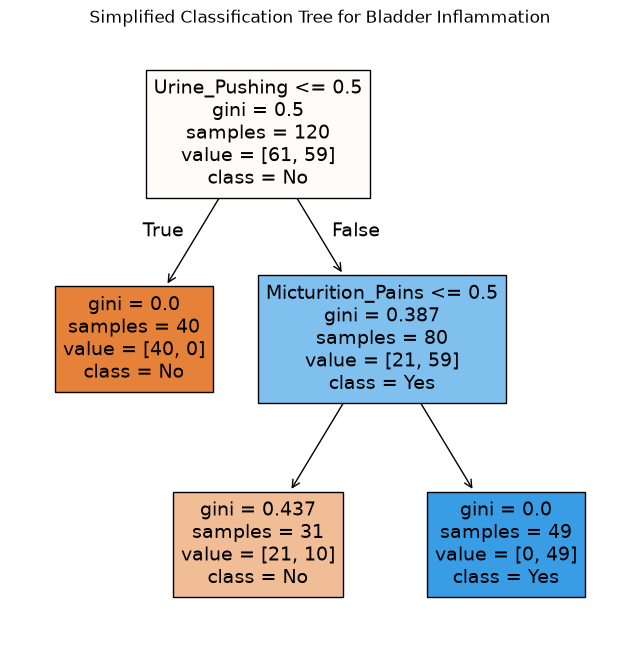

In [13]:
# Retain the smallest candidate that correctly classifies at least 90% of these patients.
compact_bladder_tree = min((fitted_tree for fitted_tree in bladder_candidates if fitted_tree.score(symptom_matrix, bladder_response) >= 0.9), key=lambda fitted_tree: fitted_tree.tree_.node_count)
print('Chosen pruning penalty:', compact_bladder_tree.ccp_alpha)
print('Total tree nodes:', compact_bladder_tree.tree_.node_count)
print('Maximum tree depth:', compact_bladder_tree.get_depth())
print('Accuracy on the complete patient dataset:', compact_bladder_tree.score(symptom_matrix, bladder_response))
plt.figure(figsize=(8, 8))
plot_tree(compact_bladder_tree, feature_names=symptom_matrix.columns, class_names=['No', 'Yes'], filled=True)
plt.title('Simplified Classification Tree for Bladder Inflammation')
plt.show()


In [14]:
# Read the simplified bladder rules from the selected classifier.
print('Bladder inflammation: rules after pruning')
print(export_text(compact_bladder_tree, feature_names=list(symptom_matrix.columns)))
describe_leaf_rules(compact_bladder_tree, list(symptom_matrix.columns), ['No', 'Yes'])


Bladder inflammation: rules after pruning
|--- Urine_Pushing <= 0.50
|   |--- class: 0
|--- Urine_Pushing >  0.50
|   |--- Micturition_Pains <= 0.50
|   |   |--- class: 0
|   |--- Micturition_Pains >  0.50
|   |   |--- class: 1

IF Urine_Pushing <= 0.50 THEN No
IF Urine_Pushing > 0.50 AND Micturition_Pains <= 0.50 THEN No
IF Urine_Pushing > 0.50 AND Micturition_Pains > 0.50 THEN Yes


In [15]:
# Construct and summarize the nephritis pruning-path candidates.
kidney_pruning_path = kidney_classifier.cost_complexity_pruning_path(symptom_matrix, kidney_response)
kidney_penalties = kidney_pruning_path.ccp_alphas
kidney_candidates = []
for pruning_penalty in kidney_penalties:
    candidate_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=pruning_penalty)
    candidate_tree.fit(symptom_matrix, kidney_response)
    kidney_candidates.append(candidate_tree)
for candidate_index in range(len(kidney_candidates)):
    candidate_tree = kidney_candidates[candidate_index]
    print(f'pruning penalty={kidney_penalties[candidate_index]:.10f}, nodes={candidate_tree.tree_.node_count}, depth={candidate_tree.tree_.max_depth}, accuracy on supplied patients={candidate_tree.score(symptom_matrix, kidney_response):.4f}')


pruning penalty=0.0000000000, nodes=5, depth=2, accuracy on supplied patients=1.0000
pruning penalty=0.1388888889, nodes=3, depth=1, accuracy on supplied patients=0.9167
pruning penalty=0.3472222222, nodes=1, depth=0, accuracy on supplied patients=0.5833


Chosen pruning penalty: 0.1388888888888889
Total tree nodes: 3
Maximum tree depth: 1
Accuracy on the complete patient dataset: 0.9166666666666666


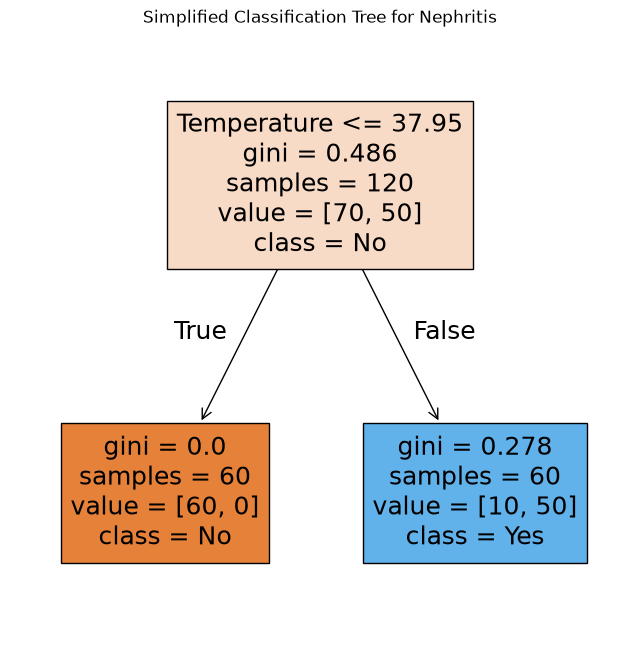

In [16]:
# Apply the same 90% training-accuracy requirement to the nephritis tree.
compact_kidney_tree = min((fitted_tree for fitted_tree in kidney_candidates if fitted_tree.score(symptom_matrix, kidney_response) >= 0.9), key=lambda fitted_tree: fitted_tree.tree_.node_count)
print('Chosen pruning penalty:', compact_kidney_tree.ccp_alpha)
print('Total tree nodes:', compact_kidney_tree.tree_.node_count)
print('Maximum tree depth:', compact_kidney_tree.get_depth())
print('Accuracy on the complete patient dataset:', compact_kidney_tree.score(symptom_matrix, kidney_response))
plt.figure(figsize=(8, 8))
plot_tree(compact_kidney_tree, feature_names=symptom_matrix.columns, class_names=['No', 'Yes'], filled=True)
plt.title('Simplified Classification Tree for Nephritis')
plt.show()


In [17]:
# Print the final, shorter nephritis rule set.
print('Nephritis: rules after pruning')
print(export_text(compact_kidney_tree, feature_names=list(symptom_matrix.columns)))
describe_leaf_rules(compact_kidney_tree, list(symptom_matrix.columns), ['No', 'Yes'])


Nephritis: rules after pruning
|--- Temperature <= 37.95
|   |--- class: 0
|--- Temperature >  37.95
|   |--- class: 1

IF Temperature <= 37.95 THEN No
IF Temperature > 37.95 THEN Yes


### Interpretation of pruning

To shorten the decision rules, I retained the smallest pruning-path candidate whose accuracy on the supplied patient records is at least **90%**. The selected penalties come directly from the pruning paths, so rounding cannot change the fitted structures.

- For **bladder inflammation**, alpha is **0.1129032258**. The model shrinks from **7 to 5 nodes**, and its depth falls from **3 to 2**.
- For **nephritis**, alpha is **0.1388888889**. The model shrinks from **5 to 3 nodes**, and its depth falls from **2 to 1**.
- Each full tree fits **100%** of these records correctly. Both reduced trees achieve **91.67%** training accuracy.

Any smaller candidate on the corresponding path fails the stated accuracy requirement. Thus, minimality is relative to this set of candidates and this chosen threshold. Simpler rules are obtained by accepting some classification mistakes, and these training scores do not measure performance on new patients.


# 2. The LASSO and Boosting for Regression

### (a) Download the Communities and Crime data. Use the first 1495 rows of data as the training set and the rest as the test set.

Read the community records in their supplied order. The required split is
applied below with `.iloc[:1495]` for model fitting and `.iloc[1495:]` for the
holdout partition; the observations are not randomly rearranged.


In [18]:
# Attach the documented field labels to the supplied crime records.
community_records = pd.read_csv(locate_dataset('communities.data'), sep=',', header=None)
community_fields = ['state', 'county', 'community', 'communityName', 'fold', 'population', 'householdSize', 'racePctBlack', 'racePctWhite', 'racePctAsian', 'racePctHisp', 'agePct12to21', 'agePct12to29', 'agePct16to24', 'agePct65Up', 'numUrban', 'pctUrban', 'medIncome', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'perCapInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'asianPerCap', 'otherPerCap', 'hispPerCap', 'numUnderPov', 'pctPopUnderPov', 'pctLess9thGrade', 'pctNotHSGrad', 'pctBSorMore', 'pctUnemployed', 'pctEmploy', 'pctEmplManu', 'pctEmplProfServ', 'pctOccupManu', 'pctOccupMgmtProf', 'malePctDivorce', 'malePctNeverMarried', 'femalePctDiv', 'totalPctDiv', 'persPerFam', 'pctFam2Par', 'pctKids2Par', 'pctYoungKids2Par', 'pctTeen2Par', 'pctWorkMomYoungKids', 'pctWorkMom', 'numIlleg', 'pctIlleg', 'numImmig', 'pctImmigRecent', 'pctImmigRec5', 'pctImmigRec8', 'pctImmigRec10', 'pctRecentImmig', 'pctRecImmig5', 'pctRecImmig8', 'pctRecImmig10', 'pctSpeakEnglOnly', 'pctNotSpeakEnglWell', 'pctLargeHouseFam', 'pctLargeHouseOccup', 'persPerOccupHouse', 'persPerOwnOccHouse', 'persPerRentOccHouse', 'pctPersOwnOccup', 'pctPersDenseHouse', 'pctHouseLess3BR', 'medNumBR', 'houseVacant', 'pctHouseOccup', 'pctHouseOwnOcc', 'pctVacantBoarded', 'pctVacMore6Months', 'medYearHouseBuilt', 'pctHouseNoPhone', 'pctNoFullPlumb', 'ownOccLowQuart', 'ownOccMedVal', 'ownOccHighQuart', 'rentLowQuart', 'rentMedian', 'rentHighQuart', 'medRent', 'medRentPctHouseInc', 'medOwnCostPctInc', 'medOwnCostPctIncNoMtg', 'numInShelters', 'numStreet', 'pctForeignBorn', 'pctBornSameState', 'pctSameHouse85', 'pctSameCity85', 'pctSameState85', 'lemasSwornFT', 'lemasSwFTPerPop', 'lemasSwFTFieldOps', 'lemasSwFTFieldPerPop', 'lemasTotalReq', 'lemasTotReqPerPop', 'policReqPerOfficer', 'policPerPop', 'racialMatchCommPol', 'pctPolicWhite', 'pctPolicBlack', 'pctPolicHisp', 'pctPolicAsian', 'pctPolicMinor', 'officAssignDrugUnits', 'numKindsDrugsSeized', 'policAvgOTWorked', 'landArea', 'popDensity', 'pctUsePubTrans', 'policCars', 'policOperBudget', 'lemasPctPolicOnPatrol', 'lemasGangUnitDeploy', 'lemasPctOfficerDrugUnit', 'policBudgetPerPop', 'violentCrimesPerPop']
community_records.columns = community_fields
community_records.head()


,state,county,community,communityName,fold,population,householdSize,racePctBlack,racePctWhite,racePctAsian,...,landArea,popDensity,pctUsePubTrans,policCars,policOperBudget,lemasPctPolicOnPatrol,lemasGangUnitDeploy,lemasPctOfficerDrugUnit,policBudgetPerPop,violentCrimesPerPop
0,8,?,?,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,?,?,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,?,?,?,?,0.00,?,0.67
2,24,?,?,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,?,?,?,?,0.00,?,0.43
3,34,5,81440,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,?,?,?,?,0.00,?,0.12
4,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,?,?,?,?,0.00,?,0.03


### (b) The data set has missing values. Use a data imputation technique to deal with the missing values in the data set. The data description mentions some features are nonpredictive. Ignore those features.

The first five fields identify records or predefined folds and are excluded
from the predictors. The cleaned data has 122 predictors and one response.
Missing entries are filled using predictor means calculated from the training
partition. The holdout data uses those same means. Copies containing the original
missing entries are retained for the model pipelines, so each CV fold learns its
own imputation values from that fold's training observations.


In [19]:
# Separate the prescribed row partitions and derive replacement means from training rows only.
community_records = community_records.replace('?', np.nan)
community_records = community_records.apply(pd.to_numeric, errors='coerce')
excluded_fields = ['state', 'county', 'community', 'communityName', 'fold']
community_records = community_records.drop(columns=excluded_fields)
community_records.head()
crime_predictors = community_records.iloc[:, :-1]
crime_response = community_records.iloc[:, -1]
training_inputs = crime_predictors.iloc[:1495].copy()
training_response = crime_response.iloc[:1495].copy()
testing_inputs = crime_predictors.iloc[1495:].copy()
testing_response = crime_response.iloc[1495:].copy()
training_inputs_raw = training_inputs.copy()
testing_inputs_raw = testing_inputs.copy()
training_column_means = training_inputs.mean()
training_inputs = training_inputs.fillna(training_column_means)
testing_inputs = testing_inputs.fillna(training_column_means)
print('Training predictor dimensions:', training_inputs.shape)
print('Holdout predictor dimensions:', testing_inputs.shape)
print('Unfilled training entries:', training_inputs.isna().sum().sum())
print('Unfilled holdout entries:', testing_inputs.isna().sum().sum())


Training predictor dimensions: (1495, 122)
Holdout predictor dimensions: (499, 122)
Unfilled training entries: 0
Unfilled holdout entries: 0


### (c) Plot a correlation matrix for the features in the data set.

The heatmap is computed from the imputed training predictors. It describes
feature–feature Pearson correlations; it does not include the crime response.
Large positive or negative values point to predictors that may contain
substantial overlapping linear information.


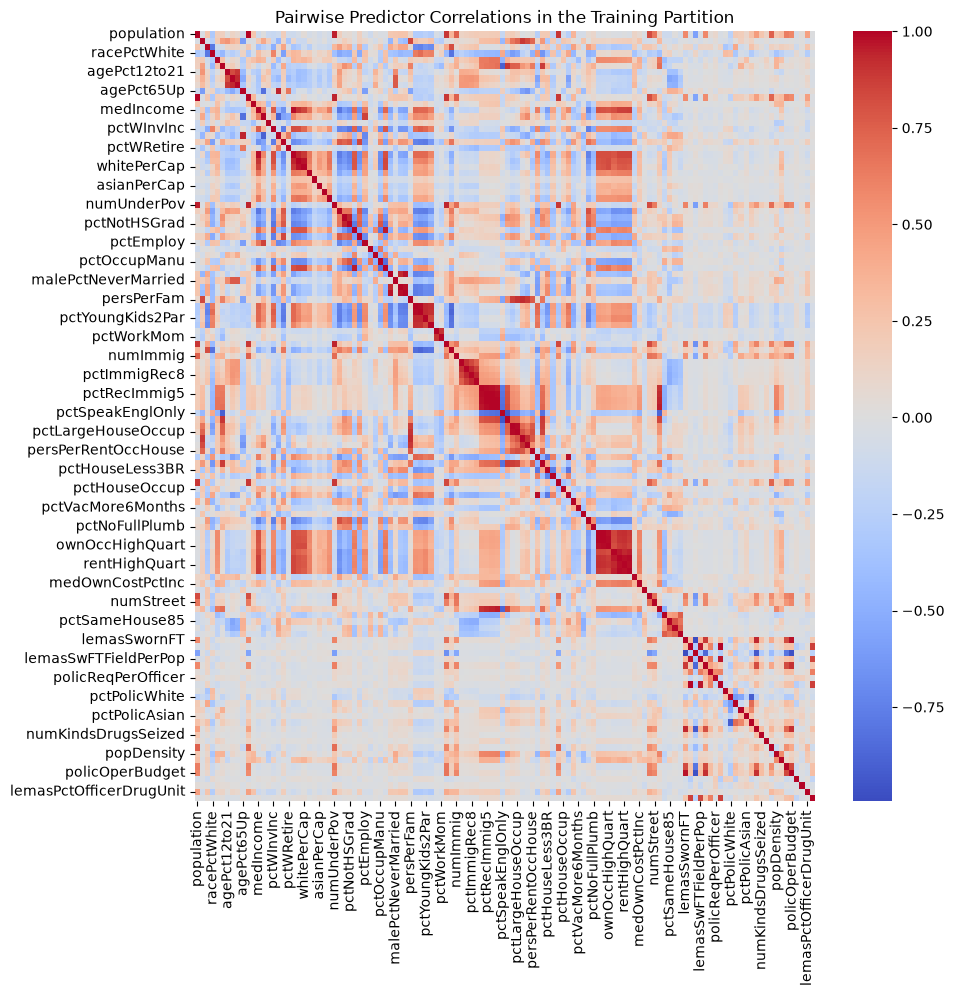

In [20]:
# Show linear associations among the imputed training predictors.
predictor_correlations = training_inputs.corr()
plt.figure(figsize=(10, 10))
sns.heatmap(predictor_correlations, cmap='coolwarm', center=0)
plt.title('Pairwise Predictor Correlations in the Training Partition')
plt.show()


### (d) Calculate the Coeﬃcient of Variation CV for each feature, where CV = s/m , in which s is sample standard deviation and m is sample mean.

For each predictor, the reported ratio is \(CV=s/\bar{x}\), where `std()` uses
sample standard deviation (`ddof=1` by default). Large ratios indicate substantial
spread relative to a feature's mean. They do not by themselves indicate an
association with the crime response. Undefined ratios are excluded from the
ranking rather than treated as zero.


In [21]:
# Measure each predictor's sample standard deviation relative to its mean.
column_averages = training_inputs.mean()
column_spreads = training_inputs.std()
relative_spread = column_spreads / column_averages
relative_spread = relative_spread.replace([np.inf, -np.inf], np.nan)
variability_summary = pd.DataFrame({'Predictor': training_inputs.columns, 'Mean': column_averages.values, 'Sample_SD': column_spreads.values, 'CV': relative_spread.values})
variability_summary = variability_summary.dropna()
with pd.option_context('display.max_rows', None):
    print(variability_summary.to_string(index=False))


              Predictor     Mean  Sample_SD       CV
             population 0.058167   0.130359 2.241105
          householdSize 0.461732   0.164284 0.355800
           racePctBlack 0.179839   0.256970 1.428885
           racePctWhite 0.752829   0.248594 0.330213
           racePctAsian 0.153712   0.208910 1.359100
            racePctHisp 0.144963   0.233694 1.612091
           agePct12to21 0.422649   0.155993 0.369083
           agePct12to29 0.492087   0.143352 0.291315
           agePct16to24 0.335425   0.167816 0.500310
             agePct65Up 0.428569   0.176903 0.412776
               numUrban 0.064649   0.131784 2.038461
               pctUrban 0.693318   0.446024 0.643318
              medIncome 0.359217   0.212649 0.591978
               pctWWage 0.553498   0.181887 0.328614
           pctWFarmSelf 0.290589   0.203964 0.701898
             pctWInvInc 0.495786   0.181128 0.365335
             pctWSocSec 0.475619   0.171563 0.360715
            pctWPubAsst 0.323445   0.228419 0.

### (e) Pick floor(sqrt(128)) features with the highest CV, make scatter plots and boxplots, and discuss whether the scatterplots establish significance.

The assignment's formula gives 11 predictors. The pairwise scatter matrix and
boxplots below describe these 11 training features. The feature ranking is
exploratory: later models still use all 122 eligible predictors.


In [22]:
# Rank the predictors by CV and take floor(sqrt(128)) = 11.
ranked_variability = variability_summary.sort_values(by='CV', ascending=False)
plot_feature_count = math.floor(math.sqrt(128))
plot_predictors = ranked_variability.head(plot_feature_count)['Predictor']
plot_predictors


90                   numStreet
89               numInShelters
49                    numIlleg
51                    numImmig
120    lemasPctOfficerDrugUnit
27                 numUnderPov
0                   population
10                    numUrban
71                 houseVacant
113                   landArea
5                  racePctHisp
Name: Predictor, dtype: str

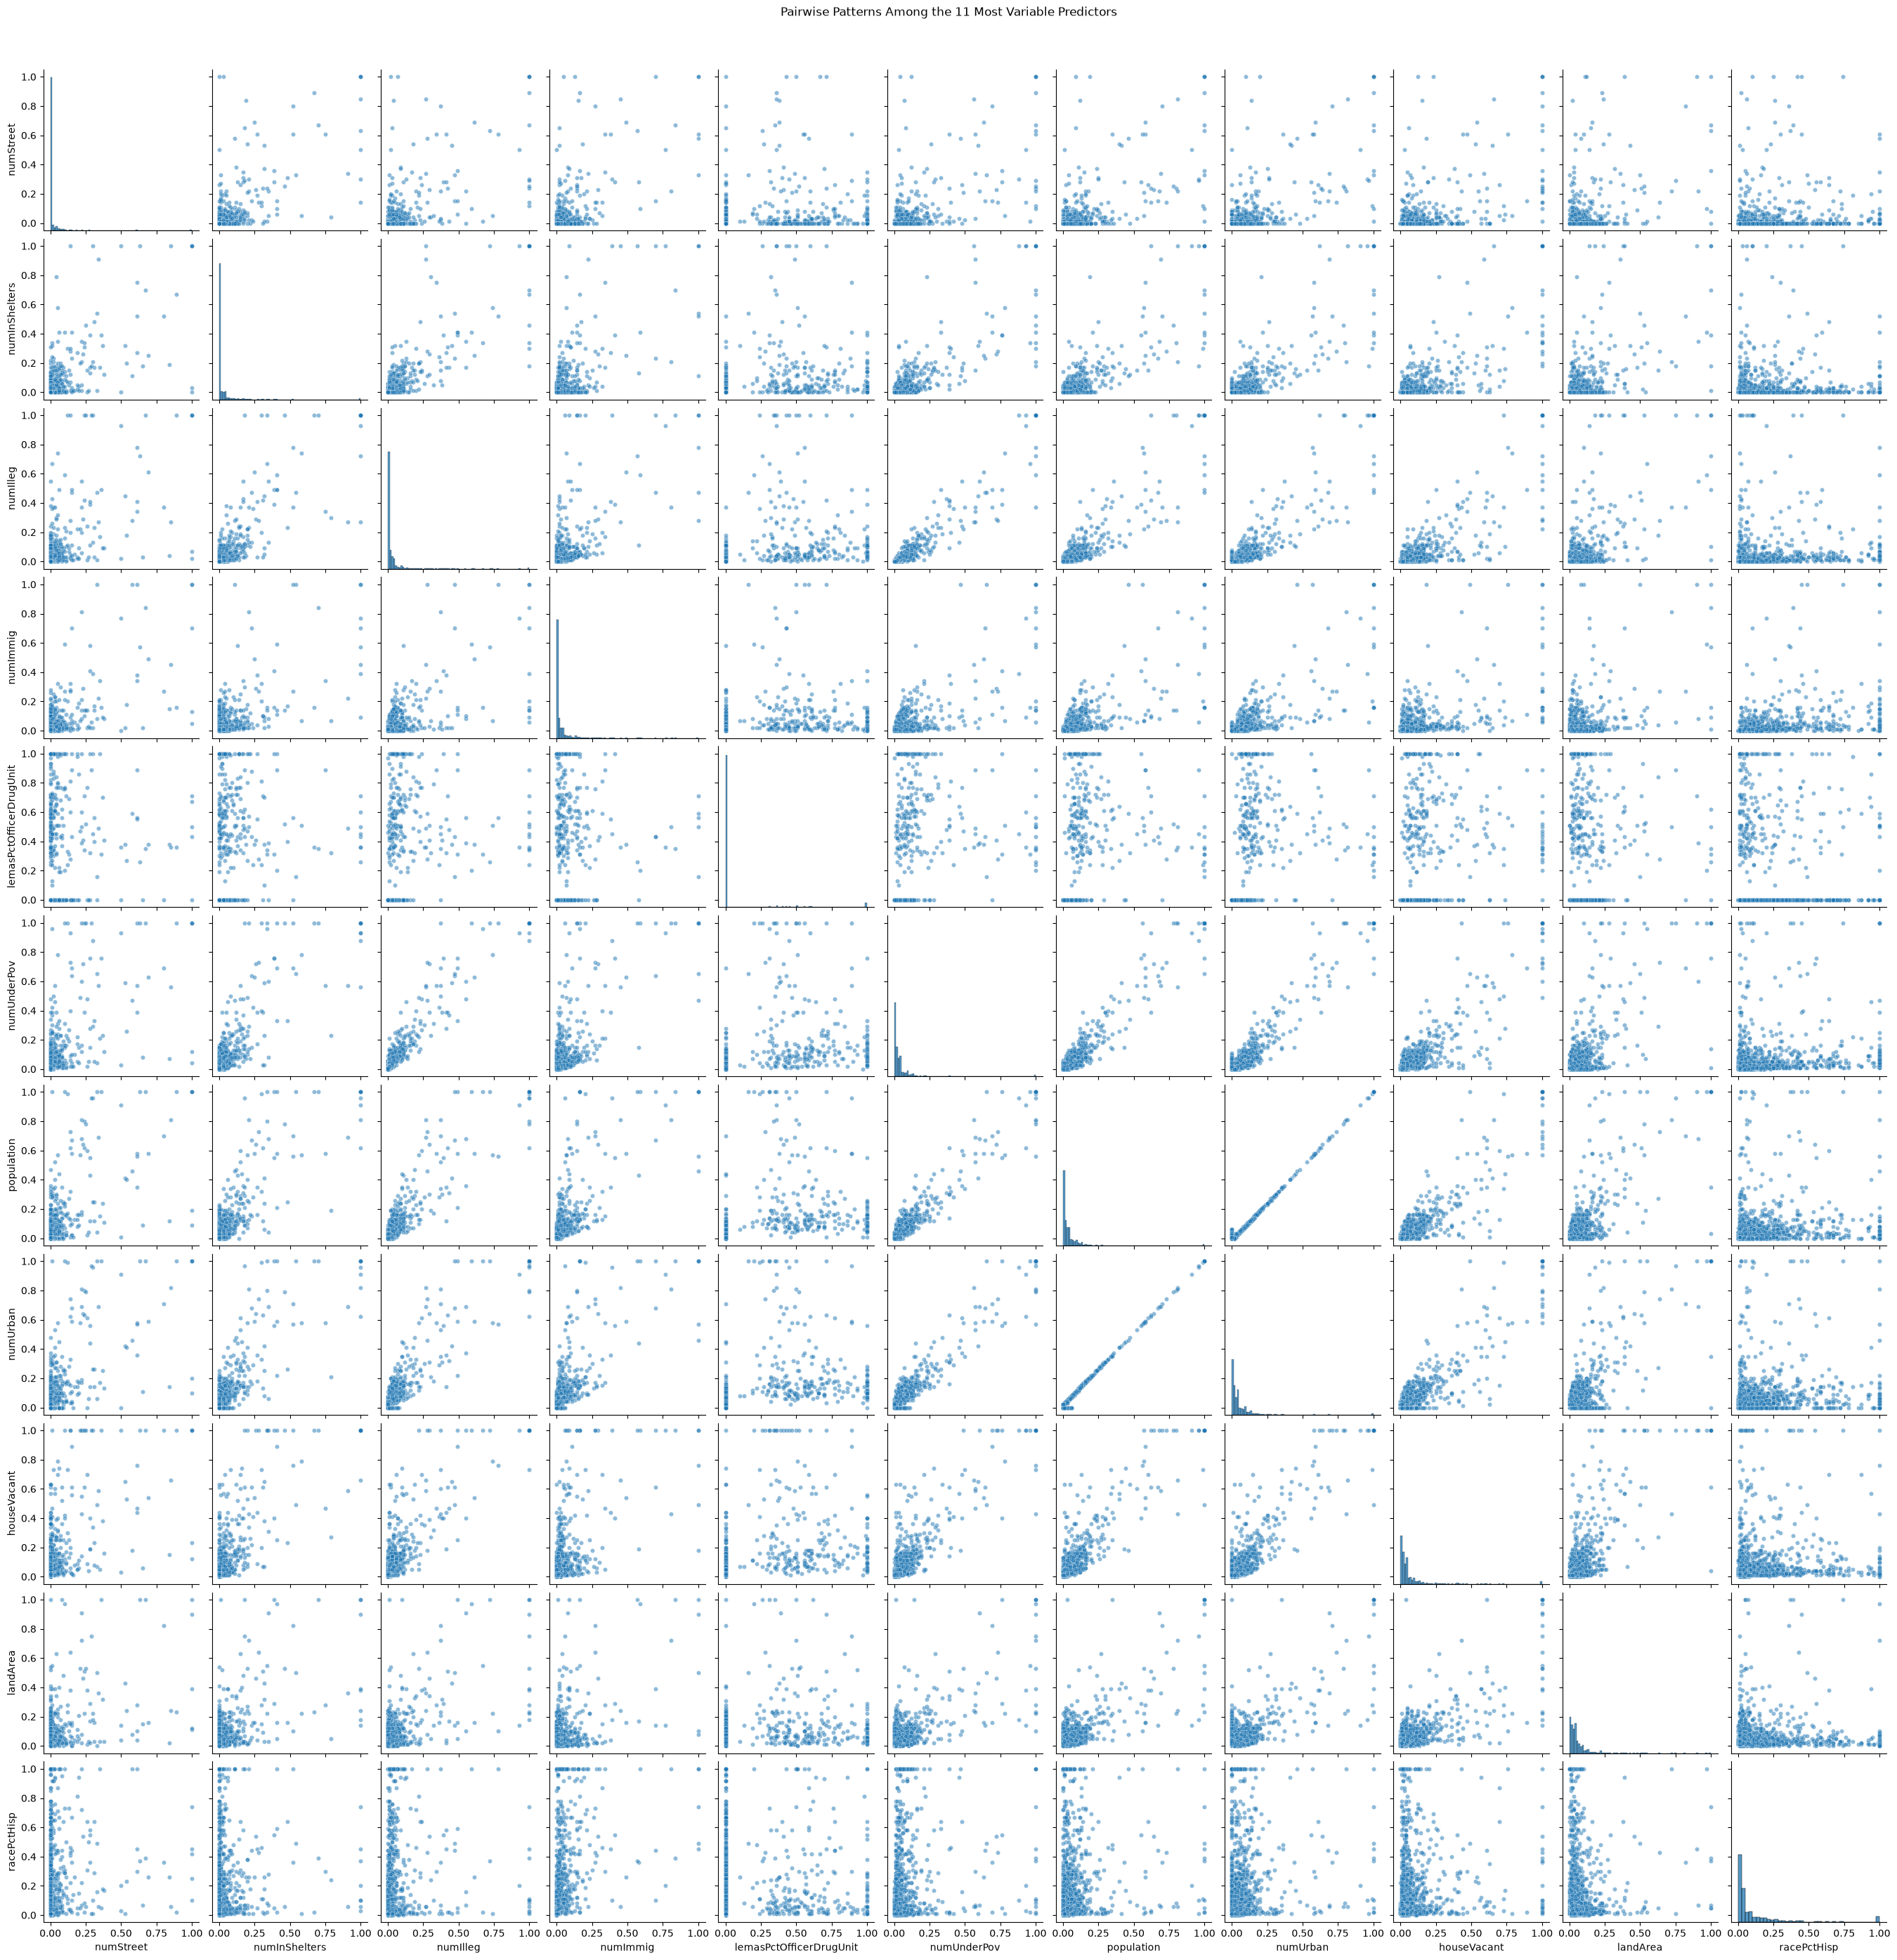

In [23]:
# Compare the selected predictor pairs visually.
plotting_inputs = training_inputs[plot_predictors]
sns.pairplot(plotting_inputs, plot_kws={'alpha': 0.5, 's': 20})
plt.suptitle('Pairwise Patterns Among the 11 Most Variable Predictors', y=1.02)
plt.show()


Several selected predictors increase together, especially population with
numUrban, population with numUnderPov, and numIlleg with numUnderPov. Their
boxplots also indicate asymmetric distributions, with many observations near
the lower end and a smaller number of large values.

These visual patterns are insufficient to declare a predictor statistically
significant. The scatter matrix compares predictor pairs, so it does not even
show each predictor's relationship with violentCrimesPerPop directly. A large CV
measures relative spread rather than predictive strength. Statistical inference
requires a specified model and its assumptions; predictive usefulness should be
assessed through validation while accounting for the other predictors.


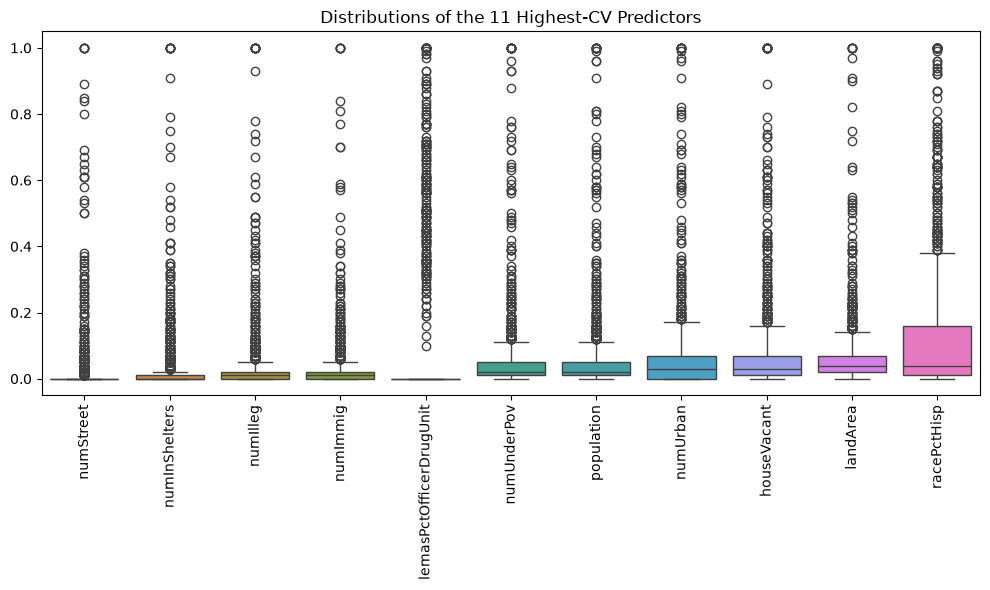

In [24]:
# Inspect spread, skew, and extreme values in the same 11 predictors.
plt.figure(figsize=(10, 6))
sns.boxplot(data=plotting_inputs)
plt.xticks(rotation=90)
plt.title('Distributions of the 11 Highest-CV Predictors')
plt.tight_layout()
plt.show()


### (f) Fit a linear model using least squares to the training set and report the test error.


In [25]:
# Estimate least-squares coefficients and evaluate the untouched holdout responses.
least_squares_fit = LinearRegression()
least_squares_fit.fit(training_inputs, training_response)
test_estimates = least_squares_fit.predict(testing_inputs)
ols_test_error = mean_squared_error(testing_response, test_estimates)
print('Test MSE:', ols_test_error)


Test MSE: 0.018141971135530104


### (g) Fit a ridge regression model on the training set, with λ chosen by cross-validation. Report the test error obtained.

A five-fold search compares the candidate L2 penalties using validation MSE.
The imputer is part of the pipeline and is fitted separately inside each fold.
After selection, the best pipeline is refitted on the complete training
partition before predicting the holdout rows. **Verified lambda:** **2.15443469**;
**verified test MSE:** **0.01761009**.


In [26]:
# Compare ridge penalties with fold-specific imputation and MSE scoring.
ridge_penalties = np.logspace(-3, 3, 100)
ridge_workflow = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('ridge', Ridge())])
ridge_tuning = GridSearchCV(ridge_workflow, {'ridge__alpha': ridge_penalties}, cv=5, scoring='neg_mean_squared_error')
ridge_tuning.fit(training_inputs_raw, training_response)
print('Best lambda (alpha):', ridge_tuning.best_params_['ridge__alpha'])
test_estimates = ridge_tuning.predict(testing_inputs_raw)
ridge_test_error = mean_squared_error(testing_response, test_estimates)
print('Test MSE (Ridge):', ridge_test_error)


Best lambda (alpha): 2.1544346900318843
Test MSE (Ridge): 0.017610091710140944


### (h) Fit a LASSO model on the training set, with λ chosen by cross-validation. Report the test error obtained, along with a list of the variables selected by the model. Repeat with standardized features. Report the test error for both cases and compare them.

#### LASSO (without standardization)

The first LASSO search uses predictors on their supplied normalized scale.
The second search adds standardization within each validation fold. Both select
lambda using the same five-fold MSE criterion. Predictors with nonzero fitted
coefficients are listed in full, and both errors use the unscaled response.


In [27]:
# Tune the L1 penalty without adding a standardization step.
lasso_penalties = np.logspace(-5, -1, 100)
plain_lasso_workflow = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('lasso', Lasso(max_iter=20000))])
plain_lasso_tuning = GridSearchCV(plain_lasso_workflow, {'lasso__alpha': lasso_penalties}, cv=5, scoring='neg_mean_squared_error')
plain_lasso_tuning.fit(training_inputs_raw, training_response)
print('Best Alpha(No Scaling):', plain_lasso_tuning.best_params_['lasso__alpha'])
plain_lasso_estimates = plain_lasso_tuning.predict(testing_inputs_raw)
plain_lasso_error = mean_squared_error(testing_response, plain_lasso_estimates)
print('Test MSE (LASSO no scaling)', plain_lasso_error)
plain_lasso_weights = pd.Series(plain_lasso_tuning.best_estimator_.named_steps['lasso'].coef_, index=training_inputs.columns)
plain_lasso_variables = plain_lasso_weights[plain_lasso_weights != 0]
print('\nPredictors retained before standardization:', len(plain_lasso_variables))
print('\nNonzero coefficients on the supplied predictor scale:')
print(plain_lasso_variables.to_string())


Best Alpha(No Scaling): 0.0001232846739442066
Test MSE (LASSO no scaling) 0.017740168189333595

Predictors retained before standardization: 75

Nonzero coefficients on the supplied predictor scale:
racePctBlack               0.271393
racePctAsian              -0.014613
agePct12to21               0.060891
agePct12to29              -0.252305
pctUrban                   0.040339
pctWWage                  -0.080903
pctWFarmSelf               0.025680
pctWInvInc                -0.095858
pctWSocSec                 0.045242
pctWPubAsst                0.037740
pctWRetire                -0.107151
whitePerCap               -0.056808
blackPerCap               -0.020685
indianPerCap              -0.030915
asianPerCap                0.028811
otherPerCap                0.022529
hispPerCap                 0.022976
pctPopUnderPov            -0.139153
pctLess9thGrade           -0.016488
pctEmploy                  0.130410
pctEmplManu               -0.014705
pctOccupManu               0.009284
malePctDiv

#### LASSO (with standardization)

In [28]:
# Learn imputation, standardization, and LASSO separately within every validation fold.
scaled_lasso_workflow = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('scaler', StandardScaler()), ('lasso', Lasso(max_iter=20000))])
scaled_lasso_tuning = GridSearchCV(scaled_lasso_workflow, {'lasso__alpha': lasso_penalties}, cv=5, scoring='neg_mean_squared_error')
scaled_lasso_tuning.fit(training_inputs_raw, training_response)
print('Best Alpha:', scaled_lasso_tuning.best_params_['lasso__alpha'])
scaled_lasso_estimates = scaled_lasso_tuning.predict(testing_inputs_raw)
scaled_lasso_error = mean_squared_error(testing_response, scaled_lasso_estimates)
print('Test MSE (LASSO scaled)', scaled_lasso_error)
scaled_lasso_weights = pd.Series(scaled_lasso_tuning.best_estimator_.named_steps['lasso'].coef_, index=training_inputs.columns)
scaled_lasso_variables = scaled_lasso_weights[scaled_lasso_weights != 0]
print('\nPredictors retained after standardization:', len(scaled_lasso_variables))
print('\nNonzero coefficients on standardized predictors:')
print(scaled_lasso_variables.to_string())


Best Alpha: 0.0007924828983539178
Test MSE (LASSO scaled) 0.017797085985464485

Predictors retained after standardization: 73

Nonzero coefficients on standardized predictors:
racePctBlack             0.068041
racePctAsian            -0.000644
agePct12to21             0.009842
agePct12to29            -0.037133
pctUrban                 0.016469
pctWWage                -0.011508
pctWFarmSelf             0.003941
pctWInvInc              -0.020602
pctWSocSec               0.008604
pctWPubAsst              0.005796
pctWRetire              -0.016996
whitePerCap             -0.008131
blackPerCap             -0.003574
indianPerCap            -0.005213
asianPerCap              0.005259
otherPerCap              0.003768
hispPerCap               0.003875
pctPopUnderPov          -0.026048
pctLess9thGrade         -0.001766
pctEmploy                0.020348
pctEmplManu             -0.000914
malePctDivorce           0.018423
malePctNeverMarried      0.019924
femalePctDiv            -0.009113
pctKids2

On the supplied predictor scale, LASSO retains **75 variables** and produces a holdout MSE of **0.01774017**. After standardization, it retains **73 variables** and the error is **0.01779709**. The unstandardized fit is slightly better on this particular holdout set, although the errors are close.

The selected penalties are **0.0001232846739** before standardization and **0.0007924828984** afterward. Scaling changes coefficient units and hence the strength of the penalty applied to each predictor. The original features lie between 0 and 1, but they do not all have the same standard deviation. Standardization therefore still affects the fitted model; it does not guarantee a smaller error or consistent variable selection among highly correlated predictors.


### (i) Fit a PCR model on the training set, with M (the number of principal components) chosen by cross-validation. Report the test error obtained.

PCR combines mean imputation, standardization, PCA, and linear regression in
one cross-validated pipeline. Every candidate component count from 1 through 122
is evaluated. The count with the smallest average validation MSE is refitted on
all training observations. **Verified selected count:** **95**;
**verified test MSE:** **0.01839293**.


In [ ]:
# Choose the PCR dimension by validating the complete preprocessing and regression pipeline.
component_workflow = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('scaler', StandardScaler()), ('pca', PCA(svd_solver='full')), ('regression', LinearRegression())])
component_tuning = GridSearchCV(component_workflow, {'pca__n_components': range(1, training_inputs.shape[1] + 1)}, cv=5, scoring='neg_mean_squared_error')
component_tuning.fit(training_inputs_raw, training_response)
chosen_component_count = component_tuning.best_params_['pca__n_components']
print('Component count chosen by training CV:', chosen_component_count)
component_estimates = component_tuning.predict(testing_inputs_raw)
component_test_error = mean_squared_error(testing_response, component_estimates)
print('PCR Test MSE:', component_test_error)


### (j) In this section, we would like to fit a boosting tree to the data. As in classification trees, one can use any type of regression at each node to build a multivariate regression tree. Because the number of variables is large in this problem, one can use L1-penalized regression at each node. Such a tree is called L1 penalized gradient boosting tree. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation.

The boosting search selects `reg_alpha` from the stated candidates by
five-fold validation MSE, with imputation learned within each fold. Other
XGBoost settings are kept fixed. In the tree booster, this L1 term penalizes
leaf weights; the standard estimator does not fit a separate multivariable
LASSO regression at each node.

**Execution note:** the displayed XGBoost result was retained from the uploaded
notebook: alpha **1**, holdout MSE **0.0177474614**. Internal names and display
labels were edited, but the estimator configuration, data processing, search
grid, and folds were preserved. These saved values were checked for consistency
with the supplied output, but could not be independently rerun because XGBoost
is unavailable in the editing environment. Rerun this cell with XGBoost installed
to confirm them on your computer.


In [ ]:
# Tune the boosting L1 penalty using the original candidates and fold-specific imputation.
from xgboost import XGBRegressor
boosting_candidates = {'xgb__reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]}
boosting_workflow = Pipeline([('imputer', SimpleImputer(strategy='mean')), ('xgb', XGBRegressor(objective='reg:squarederror', random_state=0, n_jobs=1))])
boosting_tuning = GridSearchCV(estimator=boosting_workflow, param_grid=boosting_candidates, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)
boosting_tuning.fit(training_inputs_raw, training_response)
chosen_l1_penalty = boosting_tuning.best_params_['xgb__reg_alpha']
print('Best Alpha:', chosen_l1_penalty)
tuned_boosting_workflow = boosting_tuning.best_estimator_
boosting_estimates = tuned_boosting_workflow.predict(testing_inputs_raw)
boosting_test_error = mean_squared_error(testing_response, boosting_estimates)
print('Test MSE - XG Boost:', boosting_test_error)
